# Черты личности, невербальные признаки и способности к продажам

## 1. Постановка задачи и материалы

Исследую данные 38 участников видеоинтервью.

Реализую:
1. Классификацию способностей к продажам по пяти чертам личности и сравнение с SE
2. Корреляции улыбок с экстраверсией и движений головы с чертами личности
3. Предсказание связанных черт по невербальным признакам, разделение 70/30 и сравнение моделей

В `VPTD_Dataset.csv` находятся пять оценок Big Five в диапазоне [0, 1] и SE от 1 до 5. SE является самооценкой способностей к продажам. В первом задании использую готовые оценки личности. В третьем предсказываю их только по признакам, доступным после обработки полного интервью.
Сравнение моделей проверяет предсказуемость в этой выборке.

## 2. Окружение и воспроизводимость

Фиксирую seed 42 и один вычислительный поток. Загружаю локальные файлы. Каждый запуск пересчитывает все результаты, поэтому устаревший кеш моделей не используется.

In [1]:
import os
from pathlib import Path
import sys, json, hashlib, platform, time, warnings
from importlib.metadata import version

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / 'data/raw/Tasks.ipynb').exists() else cwd / 'personality_lab'
assert (ROOT / 'data/raw/Tasks.ipynb').is_file(), 'Запускаю из ML4 или personality_lab'
DATA = ROOT / 'data'
RAW, PROCESSED, RESULTS, FIGURES = [DATA / p for p in ['raw', 'processed', 'results', 'figures']]
for p in [PROCESSED, RESULTS, FIGURES, ROOT / '.cache']:
    p.mkdir(parents=True, exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS']:
    os.environ[name] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, rankdata
from sklearn.model_selection import train_test_split, RepeatedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits, threadpool_info
from IPython.display import display, Markdown

SEED = 42
THREAD_LIMIT = threadpool_limits(limits=1)
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.family': 'DejaVu Sans'})
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def save_json(path, obj):
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def savefig(name):
    plt.savefig(FIGURES / (name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close('all')

packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'nbformat',
            'nbclient', 'ipykernel', 'threadpoolctl']
environment = {'python': sys.version, 'executable': sys.executable, 'platform': platform.platform(),
               'machine': platform.machine(), 'processor': platform.processor(),
               'logical_cpus': os.cpu_count(), 'seed': SEED, 'threads': 1,
               'packages': {p: version(p) for p in packages}, 'threadpools': threadpool_info()}
save_json(RESULTS / 'environment.json', environment)
manifest = {p.name: {'bytes': p.stat().st_size, 'sha256': hashlib.sha256(p.read_bytes()).hexdigest()}
            for p in sorted(RAW.iterdir()) if p.is_file()}
save_json(RESULTS / 'source_checksums.json', manifest)
display(pd.Series(environment['packages'], name='Версия').to_frame())
print(platform.platform(), '| CPU:', platform.machine(), '| потоков:', 1)
from sklearn.isotonic import IsotonicRegression


,Версия
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0
threadpoolctl,3.6.0


macOS-26.6.2-arm64-arm-64bit-Mach-O | CPU: arm64 | потоков: 1


## 3. Качество данных и разделение участников

Загружаю локальные таблицы и связываю их по идентификатору. У названий видео удаляю только суффикс `.mp4`, регистр сохраняю. Проверяю пропуски, дубли, диапазоны оценок, конечность углов и согласованность трёх осей.

Использую фиксированное разделение 70/30 с `random_state=42`: 26 участников train и 12 участников сравнения. Одному человеку соответствует одна строка, поэтому разделение строк одновременно разделяет людей. Для регрессии стратификация по SE не нужна. Все обучаемые преобразования и подбор параметров выполняю внутри train. Полные корреляции показываю отдельно как описательный анализ.

Сравнительная часть уже участвовала в выборе итоговых методов. Оценки на ней могут быть оптимистичны вследствие этого выбора. Состав частей сохраняю и не меняю ради улучшения чисел.

In [2]:
traits = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
people_raw = pd.read_csv(RAW / 'VPTD_Dataset.csv')
smiles_raw = pd.read_csv(RAW / 'smiles.csv')
head = json.loads((RAW / 'head_movements.json').read_text())
assert not people_raw.isna().any().any() and not smiles_raw.isna().any().any()
assert not people_raw.duplicated().any() and not smiles_raw.duplicated().any()
assert people_raw.Id_name.is_unique and smiles_raw.names.is_unique
people = people_raw.set_index('Id_name')
smiles = smiles_raw.assign(Id_name=smiles_raw.names.str.removesuffix('.mp4')).set_index('Id_name')
assert set(people.index) == set(smiles.index) == set(head)
assert people[traits].apply(lambda x: x.between(0, 1)).all().all()
assert people.SE.isin([1, 2, 3, 4, 5]).all()
assert (smiles.total_frames > 0).all()
assert (smiles.smiles >= 0).all() and (smiles.smiles <= smiles.total_frames).all()
assert np.equal(smiles[['smiles', 'total_frames']], np.floor(smiles[['smiles', 'total_frames']])).all().all()
assert all(set(v) == {'Roll', 'Pitch', 'Yaw'} for v in head.values())
assert all(len({len(x) for x in v.values()}) == 1 for v in head.values())
assert all(len(x) > 1 and np.isfinite(x).all() for v in head.values() for x in v.values())

audit = people.join(smiles[['smiles', 'total_frames']])
audit['head_samples'] = [len(head[k]['Roll']) for k in audit.index]
audit['sample_difference'] = audit.head_samples - audit.total_frames
audit['smile_ratio'] = audit.smiles / audit.total_frames
audit['zero_pose_fraction'] = [np.mean(np.array([head[k][a] for a in ['Roll','Pitch','Yaw']]).T == 0)
                               for k in audit.index]
quality = pd.DataFrame([
    ['Пропуски в CSV', int(people_raw.isna().sum().sum() + smiles_raw.isna().sum().sum()), 'Исключений нет'],
    ['Точные дубли строк CSV', int(people_raw.duplicated().sum() + smiles_raw.duplicated().sum()), 'Исключений нет'],
    ['Повторные ID внутри файла', int(people_raw.Id_name.duplicated().sum()+smiles.index.duplicated().sum()), 'Исключений нет'],
    ['Участники без соответствия', len(set(people.index) ^ set(head)), 'Связываю по ID'],
    ['Длина углов отличается от total_frames', int(audit.sample_difference.ne(0).sum()), 'Агрегирую каждый источник отдельно'],
    ['Длина углов больше total_frames', int(audit.sample_difference.gt(0).sum()), 'Не предполагаю покадровое соответствие'],
    ['Нулевое число кадров с улыбкой', int(audit.smiles.eq(0).sum()), 'Сохраняю наблюдения'],
], columns=['Проверка', 'Количество', 'Решение'])
display(quality)
quality.to_csv(RESULTS / 'quality_report.csv', index=False)
audit.to_csv(PROCESSED / 'participant_audit.csv')

train_ids, test_ids = train_test_split(people.index.to_numpy(), test_size=0.30, random_state=SEED)
assert not set(train_ids) & set(test_ids)
assert set(train_ids) | set(test_ids) == set(people.index)
split = pd.DataFrame({'Id_name': people.index, 'split': ['train' if k in train_ids else 'test' for k in people.index]})
split.to_csv(PROCESSED / 'split.csv', index=False)
display(split.groupby('split').size().rename('Участники').to_frame())
display(people[traits + ['SE']].describe().T)
display(Markdown(f"Проверил все источники и сохранил **{len(people)} участников**. Исключений не потребовалось. "
                 f"В {audit.sample_difference.ne(0).sum()} интервью длина углов отличалась от числа видеокадров, "
                 f"в {audit.sample_difference.gt(0).sum()} случаях она была больше. Метки времени отсутствовали, "
                 "поэтому я не стал считать разность пропущенными кадрами или совмещать сигналы по индексам. "
                 "Нули и экстремальные углы сохранил, так как независимого признака ошибки трекинга не было."))

,Проверка,Количество,Решение
0,Пропуски в CSV,0,Исключений нет
1,Точные дубли строк CSV,0,Исключений нет
2,Повторные ID внутри файла,0,Исключений нет
3,Участники без соответствия,0,Связываю по ID
4,Длина углов отличается от total_frames,18,Агрегирую каждый источник отдельно
5,Длина углов больше total_frames,2,Не предполагаю покадровое соответствие
6,Нулевое число кадров с улыбкой,12,Сохраняю наблюдения


,Участники
split,
test,12
train,26


,count,mean,std,min,25%,50%,75%,max
Extraversion,38.0,0.5718,0.1719,0.175,0.5000,0.5675,0.6925,0.900
Agreeableness,38.0,0.6642,0.1491,0.275,0.5563,0.6500,0.7500,0.975
Conscientiousness,38.0,0.6605,0.1470,0.400,0.5712,0.6700,0.7738,0.950
Neuroticism,38.0,0.4196,0.1757,0.075,0.2787,0.4350,0.5675,0.775
Openness,38.0,0.6713,0.1364,0.290,0.6000,0.6750,0.7400,0.975
SE,38.0,2.7632,1.1012,1.000,2.0000,3.0000,4.0000,5.000


Проверил все источники и сохранил **38 участников**. Исключений не потребовалось. В 18 интервью длина углов отличалась от числа видеокадров, в 2 случаях она была больше. Метки времени отсутствовали, поэтому я не стал считать разность пропущенными кадрами или совмещать сигналы по индексам. Нули и экстремальные углы сохранил, так как независимого признака ошибки трекинга не было.

### 3.1. Распределения

Проверяю неоднородность черт, SE и доли улыбок. Для доли улыбок использую линейную шкалу и отдельно показываю видео с нулевыми значениями. Значение `smiles` трактую как число кадров с улыбкой, как описано в лекции, а не как число отдельных эпизодов улыбки.

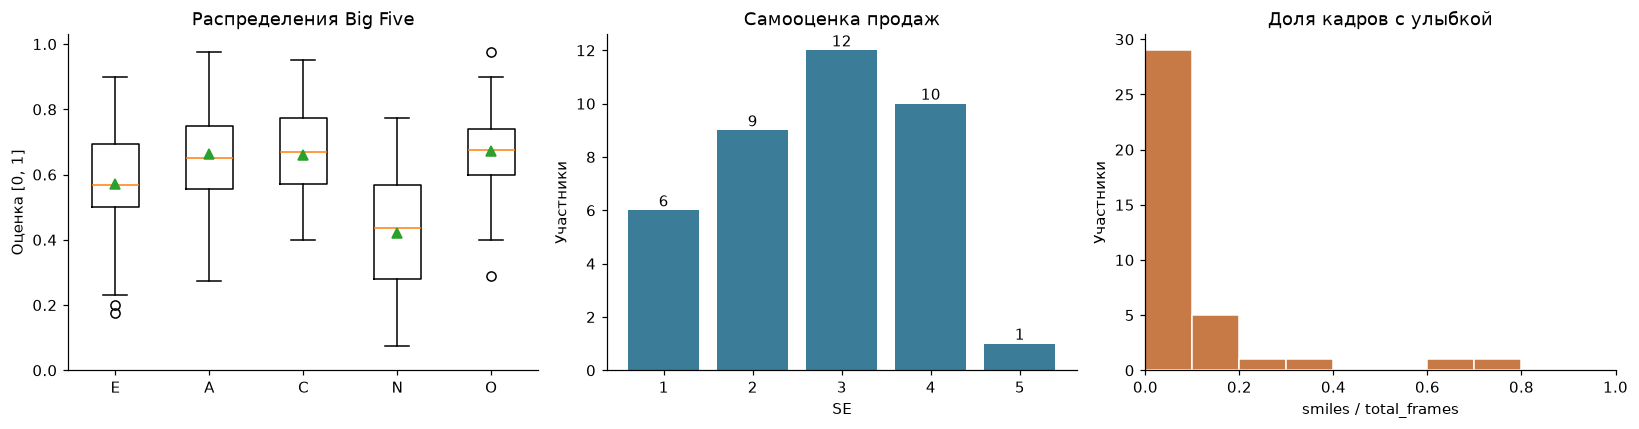

Получил распределение SE **{1: 6, 2: 9, 3: 12, 4: 10, 5: 1}**. Уровень 5 встретился только один раз, поэтому отдельные оценки качества этого класса ненадёжны. Без улыбок оказалось 12 видео. Доли улыбок варьировались от 0.000 до 0.753. Длительности интервью различались, поэтому основным признаком улыбок выбрал долю кадров. Малый объём выборки учёл ограничением числа признаков и регуляризацией моделей.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].boxplot([people[t] for t in traits], tick_labels=['E','A','C','N','O'], showmeans=True)
axes[0].set(title='Распределения Big Five', ylabel='Оценка [0, 1]', ylim=(0, 1.03))
counts = people.SE.value_counts().reindex(range(1,6), fill_value=0).sort_index()
axes[1].bar(counts.index, counts.values, color='#3b7d99')
axes[1].set(title='Самооценка продаж', xlabel='SE', ylabel='Участники', xticks=range(1,6))
for x, y in counts.items(): axes[1].text(x, y + .15, str(y), ha='center')
axes[2].hist(audit.smile_ratio, bins=np.linspace(0,1,11), color='#c77946', edgecolor='white')
axes[2].set(title='Доля кадров с улыбкой', xlabel='smiles / total_frames', ylabel='Участники', xlim=(0,1))
plt.tight_layout()
savefig('01_distributions')
display(Markdown(f"Получил распределение SE **{counts.to_dict()}**. Уровень 5 встретился только один раз, "
                 "поэтому отдельные оценки качества этого класса ненадёжны. "
                 f"Без улыбок оказалось {audit.smiles.eq(0).sum()} видео. Доли улыбок варьировались от "
                 f"{audit.smile_ratio.min():.3f} до {audit.smile_ratio.max():.3f}. "
                 "Длительности интервью различались, поэтому основным признаком улыбок выбрал долю кадров. "
                 "Малый объём выборки учёл ограничением числа признаков и регуляризацией моделей."))

## 4. Задание 1. Классификация способностей к продажам

Строю прозрачный балл по гипотезе задания. Положительно учитываю экстраверсию E, добросовестность C и открытость O. Отрицательно учитываю доброжелательность A и нейротизм N.

$$s=[E+C+O+(1-A)+(1-N)]/5.$$

Для исходного правила использую класс $\min(5,1+\lfloor5s\rfloor)$ на равных интервалах шириной 0,2. Порог 1 входит в класс 5. Гипотезу не считаю установленной психологической закономерностью.

В итоговой системе обучаю монотонное соответствие между s и SE через IsotonicRegression. Оно сохраняет направление балла и калибрует его к шкале самооценки. При выходе s за обучающий диапазон беру крайнее значение. Прогноз округляю к ближайшему целому, половины вверх, и ограничиваю классами 1–5. Для baseline использую моду SE на train, при равных частотах выбираю меньший класс.

Сравниваю исходное правило, калибровку и baseline на одинаковых 5 фолдах с тремя повторами внутри train. Калибровку каждый раз обучаю только на обучающей части фолда. У метода нет подбираемого параметра сложности. Итоговый способ фиксирую как калибровку до исполнения этой версии.

Оцениваю accuracy, macro-F1 с пятью фиксированными классами и `zero_division=0`, MAE в баллах SE и долю ошибок не больше одного балла. Accuracy, F1 и доля малых ошибок выше лучше, MAE ниже лучше. Непрерывный s не является вероятностью. Согласие с SE не равно точности предсказания реальных продаж.

,MAE,accuracy
method,,
Исходное правило,0.6578,0.5000
Калибровка,0.6400,0.4622
Мода train,0.9867,0.2244


,scope,method,n,applied,accuracy,macro_F1,MAE,within_one
0,"Все, описательно",Исходное правило,38,False,0.4474,0.2402,0.7105,0.8421
1,"Все, описательно",Калибровка,38,True,0.5526,0.3667,0.5000,0.9474
2,"Все, описательно",Мода train,38,False,0.3158,0.0960,0.8684,0.8158
3,Сравнительная выборка,Исходное правило,12,False,0.3333,0.1870,0.8333,0.8333
4,Сравнительная выборка,Калибровка,12,True,0.5000,0.3343,0.5833,0.9167
5,Сравнительная выборка,Мода train,12,False,0.2500,0.0800,1.0000,0.7500


,precision,recall,f1-score,support
1,0.0000,0.0000,0.0000,2.0
2,0.4286,1.0000,0.6000,3.0
3,1.0000,0.3333,0.5000,3.0
4,0.5000,0.6667,0.5714,3.0
5,0.0000,0.0000,0.0000,1.0
accuracy,0.5000,0.5000,0.5000,0.5
macro avg,0.3857,0.4000,0.3343,12.0
weighted avg,0.4821,0.5000,0.4179,12.0


SE,1,2,3,4,5
split,,,,,
test,2,3,3,3,1
train,4,6,9,7,0


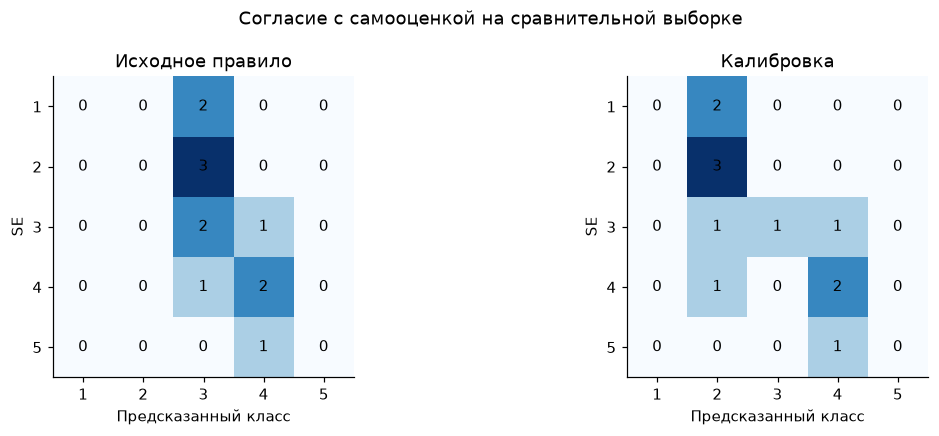

Применил калибровку и получил accuracy **0.500**, macro-F1 **0.334**, MAE **0.583 балла SE**. Исходное правило получило accuracy 0.333 и MAE 0.833. Условный 95% парный bootstrap-интервал разности MAE составил [-0.667, +0.167]. Он включал ноль, поэтому уверенного переноса улучшения на новых участников не подтвердил. Класс 5 отсутствовал в train и был представлен единственным участником сравнения. Калибровка не могла выдать этот верхний класс.

In [4]:
def sales_score(frame):
    return (frame.Extraversion+frame.Conscientiousness+frame.Openness+
            1-frame.Agreeableness+1-frame.Neuroticism)/5

def sales_class(score):
    return np.clip(1+np.floor(5*np.asarray(score)).astype(int),1,5)

def ordinal_labels(pred):
    return np.clip(np.floor(np.asarray(pred)+.5),1,5).astype(int)

assert np.array_equal(sales_class([0,.1999,.2,.4,.6,.8,1]),[1,1,2,3,4,5,5])
score=sales_score(people)
sales_cv=list(RepeatedKFold(n_splits=5,n_repeats=3,random_state=SEED).split(train_ids))
sales_cv_rows=[]
for fold,(a,b) in enumerate(sales_cv):
    ya=people.loc[train_ids[a],'SE']
    yb=people.loc[train_ids[b],'SE']
    iso=IsotonicRegression(out_of_bounds='clip').fit(score.loc[train_ids[a]].to_numpy(),ya)
    predictions_fold={
        'Исходное правило':sales_class(score.loc[train_ids[b]]),
        'Калибровка':ordinal_labels(iso.predict(score.loc[train_ids[b]].to_numpy())),
        'Мода train':np.repeat(int(ya.mode().min()),len(b))}
    for method,pred in predictions_fold.items():
        sales_cv_rows.append({'fold':fold,'method':method,'MAE':mean_absolute_error(yb,pred),
                              'accuracy':accuracy_score(yb,pred)})
sales_cv_results=pd.DataFrame(sales_cv_rows)
sales_cv_results.to_csv(RESULTS/'sales_cv.csv',index=False)
display(sales_cv_results.groupby('method')[['MAE','accuracy']].mean())

calibrator=IsotonicRegression(out_of_bounds='clip').fit(score.loc[train_ids].to_numpy(),people.loc[train_ids,'SE'])
sales=people[['SE']].assign(score=score,rule_class=sales_class(score),
                           calibrated_class=ordinal_labels(calibrator.predict(score.to_numpy())),
                           baseline_class=int(people.loc[train_ids,'SE'].mode().min()))
sales['split']=split.set_index('Id_name')['split']
sales['absolute_error']=abs(sales.SE-sales.calibrated_class)
sales.to_csv(RESULTS/'sales_predictions.csv')

def classification_metrics(y,pred):
    return {'accuracy':accuracy_score(y,pred),
            'macro_F1':f1_score(y,pred,labels=[1,2,3,4,5],average='macro',zero_division=0),
            'MAE':mean_absolute_error(y,pred),'within_one':np.mean(np.abs(y-pred)<=1)}

sales_methods={'Исходное правило':'rule_class','Калибровка':'calibrated_class','Мода train':'baseline_class'}
sales_metrics=pd.DataFrame([
    {'scope':label,'method':method,'n':len(ids),'applied':method=='Калибровка',
     **classification_metrics(sales.loc[ids,'SE'],sales.loc[ids,col])}
    for label,ids in [('Все, описательно',people.index),('Сравнительная выборка',test_ids)]
    for method,col in sales_methods.items()])
sales_metrics.to_csv(RESULTS/'sales_metrics.csv',index=False)
display(sales_metrics)
display(pd.DataFrame(classification_report(sales.loc[test_ids,'SE'],sales.loc[test_ids,'calibrated_class'],
                                          labels=[1,2,3,4,5],output_dict=True,zero_division=0)).T)
display(pd.crosstab(sales['split'],sales.SE).reindex(columns=range(1,6),fill_value=0))

fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,method in zip(axes,['Исходное правило','Калибровка']):
    cm=confusion_matrix(sales.loc[test_ids,'SE'],sales.loc[test_ids,sales_methods[method]],labels=[1,2,3,4,5])
    ax.imshow(cm,cmap='Blues')
    for i in range(5):
        for j in range(5):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
    ax.set(title=method,xticks=range(5),yticks=range(5),xticklabels=range(1,6),yticklabels=range(1,6),
           xlabel='Предсказанный класс',ylabel='SE')
plt.suptitle('Согласие с самооценкой на сравнительной выборке')
plt.tight_layout()
savefig('02_sales')

sales_final=sales_metrics.query("scope == 'Сравнительная выборка' and applied").iloc[0]
sales_rule=sales_metrics.query("scope == 'Сравнительная выборка' and method == 'Исходное правило'").iloc[0]
sales_difference=(abs(sales.loc[test_ids,'SE']-sales.loc[test_ids,'calibrated_class'])-
                  abs(sales.loc[test_ids,'SE']-sales.loc[test_ids,'rule_class'])).to_numpy()
idx=np.random.default_rng(SEED).integers(0,len(test_ids),size=(5000,len(test_ids)))
sales_low,sales_high=np.quantile(sales_difference[idx].mean(axis=1),[.025,.975])
save_json(RESULTS/'sales_bootstrap.json',{'delta_MAE':float(sales_difference.mean()),
          'CI95_low':float(sales_low),'CI95_high':float(sales_high),'repeats':5000,
          'unit':'participant','comparison_used_for_selection':True})
display(Markdown(f"Применил калибровку и получил accuracy **{sales_final.accuracy:.3f}**, "
                 f"macro-F1 **{sales_final.macro_F1:.3f}**, MAE **{sales_final.MAE:.3f} балла SE**. "
                 f"Исходное правило получило accuracy {sales_rule.accuracy:.3f} и MAE {sales_rule.MAE:.3f}. "
                 f"Условный 95% парный bootstrap-интервал разности MAE составил "
                 f"[{sales_low:+.3f}, {sales_high:+.3f}]. Он включал ноль, поэтому уверенного переноса "
                 "улучшения на новых участников не подтвердил. Класс 5 отсутствовал в train и был "
                 "представлен единственным участником сравнения. Калибровка не могла выдать этот верхний класс."))

## 5. Задание 2. Извлечение невербальных признаков

Для каждого участника вычисляю долю кадров с улыбкой. Для каждой оси головы получаю среднее, стандартное отклонение с `ddof=0`, минимум, максимум, среднее абсолютное изменение между соседними записями и два признака событий. Всего получаю 22 признака, только из невербальных источников.

Событием считаю непрерывный участок, на котором $|x-\bar x|>\sigma$. Сохраняю долю записей вне границ и число начал таких участков на 1000 записей. При нулевом стандартном отклонении события отсутствуют. Порог в одно стандартное отклонение фиксирую по примеру лекции, без подбора. Среднее и σ рассчитываю внутри одного интервью, это признаки доступного целиком объекта.

,smile_ratio,Roll_mean,Roll_std,Roll_min,Roll_max,Roll_mean_abs_diff,...,Yaw_std,Yaw_min,Yaw_max,Yaw_mean_abs_diff,Yaw_outside_fraction,Yaw_events_per_1000
Id_name,,,,,,,,,,,,,
wzewmMk_Nzv,0.0076,1.7495,2.2748,-6.99,8.47,0.3145,...,10.0842,-33.98,20.34,0.5384,0.1580,10.1138
MKdgEMd_con,0.0000,6.7386,6.6734,-12.23,27.94,0.4776,...,9.8987,-27.82,31.81,0.5592,0.2856,12.9952
pjlESEZ_rgA,0.0036,-0.5136,5.1723,-12.80,10.18,0.4656,...,3.2813,-13.73,8.51,0.4852,0.2552,34.9650
HmakBQy_Zuo,0.1209,0.6277,2.0043,-5.82,7.21,0.2565,...,1.8541,0.88,12.14,0.2337,0.3095,26.5957
PMoGeaZ_lek,0.0000,-1.1822,1.0202,-4.44,2.67,0.2853,...,1.8099,0.06,9.90,0.2884,0.3252,45.7644


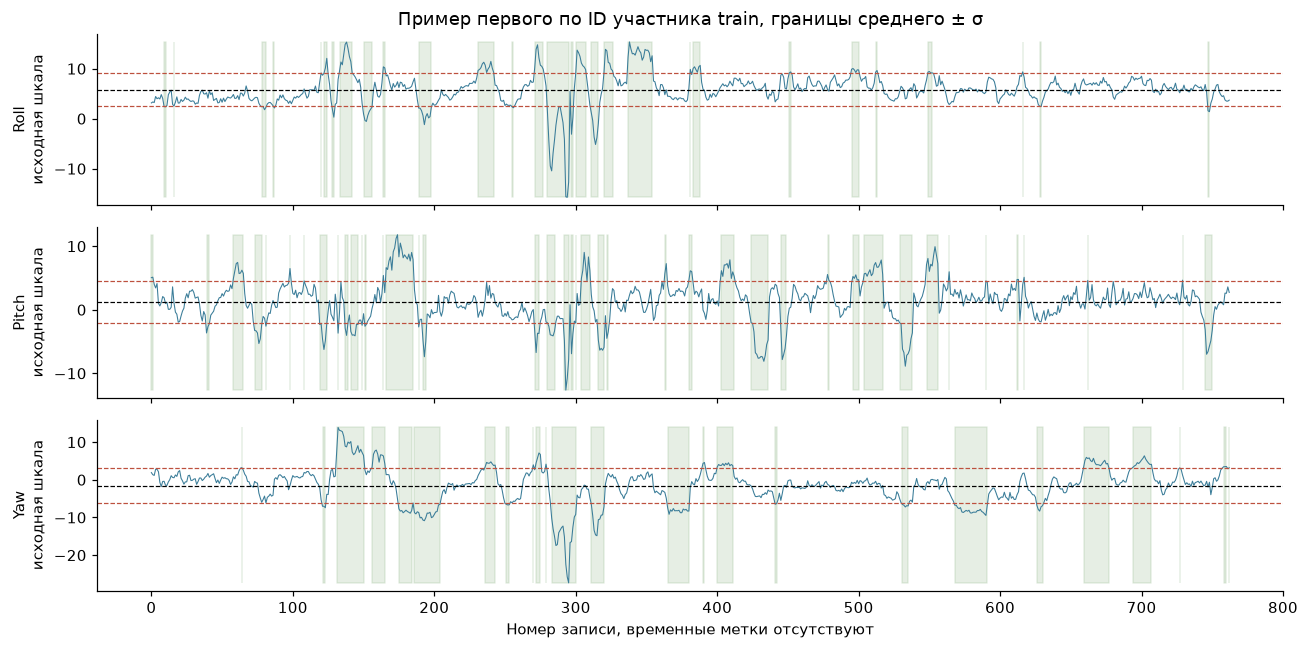

Извлёк 22 признака для 38 участников. Не стал исключать редкие движения по величине угла. Пример выбрал по первому ID train, а не по силе корреляции. Для небольшого train в дальнейшем ограничил число признаков внутри каждого фолда кросс-валидации.

In [5]:
def axis_features(values):
    x = np.asarray(values, dtype=float)
    mu, sd = x.mean(), x.std(ddof=0)
    outside = np.abs(x - mu) > sd if sd > 0 else np.zeros(len(x), dtype=bool)
    starts = outside & ~np.r_[False, outside[:-1]]
    return {'mean': mu, 'std': sd, 'min': x.min(), 'max': x.max(),
            'mean_abs_diff': np.abs(np.diff(x)).mean(),
            'outside_fraction': outside.mean(), 'events_per_1000': starts.sum()/len(x)*1000}

check = axis_features([0, 0, 0, 4])
assert check['outside_fraction'] == .25 and check['events_per_1000'] == 250
assert axis_features([2,2,2])['events_per_1000'] == 0

rows = []
for key in people.index:
    row = {'Id_name': key, 'smile_ratio': audit.loc[key, 'smile_ratio']}
    for axis in ['Roll','Pitch','Yaw']:
        row.update({axis+'_'+name: value for name, value in axis_features(head[key][axis]).items()})
    rows.append(row)
features = pd.DataFrame(rows).set_index('Id_name')
assert features.shape == (len(people), 22)
assert np.isfinite(features).all().all()
assert set(features.columns).isdisjoint(traits + ['SE', 'Id_name', 'total_frames'])
features.to_csv(PROCESSED / 'nonverbal_features.csv')
display(features.head())

example_id = sorted(train_ids)[0]
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, axis in zip(axes, ['Roll','Pitch','Yaw']):
    x = np.asarray(head[example_id][axis])
    mu, sd = x.mean(), x.std()
    out = np.abs(x-mu)>sd
    ax.plot(x, lw=.7, color='#3b7d99')
    ax.axhline(mu, color='black', ls='--', lw=.8)
    ax.axhline(mu+sd, color='#bd503e', ls='--', lw=.8)
    ax.axhline(mu-sd, color='#bd503e', ls='--', lw=.8)
    ax.fill_between(np.arange(len(x)), x.min(), x.max(), where=out, color='#82ad78', alpha=.2)
    ax.set_ylabel(axis + '\nисходная шкала')
axes[0].set_title('Пример первого по ID участника train, границы среднего ± σ')
axes[-1].set_xlabel('Номер записи, временные метки отсутствуют')
plt.tight_layout()
savefig('03_head_events')
display(Markdown(f"Извлёк {features.shape[1]} признака для {features.shape[0]} участников. "
                 "Не стал исключать редкие движения по величине угла. Пример выбрал по первому ID train, "
                 "а не по силе корреляции. Для небольшого train в дальнейшем ограничил число признаков "
                 "внутри каждого фолда кросс-валидации."))

### 5.1. Корреляции только на train и выбор целей

Исследую связи на 26 обучающих участниках. Для каждой пары вычисляю Pearson r и Spearman ρ. В таблице показываю двустороннее параметрическое p-value Пирсона как дополнительную оценку. Основным считаю Spearman, поскольку распределения асимметричны и содержат много совпадающих значений.

Для Spearman использую двусторонний перестановочный тест с 4999 перестановками целевых строк и формулой $(1+N_{|\rho_b|\ge|\rho|})/(B+1)$. Строки переставляю целиком, сохраняя зависимости между целями. Корректирую p-values методом Benjamini–Hochberg по всем 22 × 5 = 110 проверкам. Порог q≤0,05 задаю заранее.

Для задания 3 сохраняю две черты, определённые по наибольшему абсолютному Spearman среди невербальных признаков на train. Равенства разрешаю по названию черты. Выбор по максимуму может завышать наблюдаемую связь, поэтому отдельно показываю q-values и не объявляю эти цели доказанно связанными. Тестовые участники в выборе целей не участвуют. При отсутствии значимых связей всё равно проверяю исследовательские гипотезы моделями и допускаю отрицательный результат.

In [6]:
PERMUTATIONS = 4999

def bh_adjust(p):
    p = np.asarray(p, dtype=float)
    order = np.argsort(p, kind='stable')
    adjusted = np.minimum.accumulate((p[order] * len(p) / np.arange(1,len(p)+1))[::-1])[::-1]
    result = np.empty_like(p)
    result[order] = np.clip(adjusted, 0, 1)
    return result

assert np.allclose(bh_adjust([.01,.04,.03]), [.03,.04,.04])

def correlation_table(x, y, seed=SEED):
    xr = np.column_stack([rankdata(x[c]) for c in x])
    yr = np.column_stack([rankdata(y[c]) for c in y])
    xr = xr - xr.mean(axis=0)
    yr = yr - yr.mean(axis=0)
    xr = xr / np.linalg.norm(xr, axis=0)
    yr = yr / np.linalg.norm(yr, axis=0)
    observed = xr.T @ yr
    rng = np.random.default_rng(seed)
    exceed = np.zeros_like(observed, dtype=int)
    for start in range(0, PERMUTATIONS, 500):
        b = min(500, PERMUTATIONS-start)
        perm = np.array([rng.permutation(len(x)) for _ in range(b)])
        null = np.einsum('nf,bnt->bft', xr, yr[perm], optimize=True)
        exceed += (np.abs(null) >= np.abs(observed)[None,:,:] - 1e-12).sum(axis=0)
    p_perm = (exceed + 1) / (PERMUTATIONS + 1)
    rows = []
    for i, f in enumerate(x):
        for j, t in enumerate(y):
            pr = pearsonr(x[f], y[t])
            rows.append({'feature': f, 'target': t, 'n': len(x), 'pearson_r': pr.statistic,
                         'pearson_p': pr.pvalue, 'spearman_rho': observed[i,j],
                         'spearman_p_perm': p_perm[i,j]})
    out = pd.DataFrame(rows)
    out['spearman_q_BH'] = bh_adjust(out.spearman_p_perm)
    out['pearson_q_BH'] = bh_adjust(out.pearson_p)
    return out

train_corr = correlation_table(features.loc[train_ids], people.loc[train_ids, traits])
train_corr.to_csv(RESULTS / 'correlations_train.csv', index=False)
train_corr['abs_rho'] = train_corr.spearman_rho.abs()
target_ranking = train_corr.sort_values(['abs_rho','target','feature'], ascending=[False,True,True]).drop_duplicates('target')
targets = target_ranking.target.head(2).tolist()
display(target_ranking[['target','feature','spearman_rho','spearman_p_perm','spearman_q_BH']])
display(train_corr.query("feature == 'smile_ratio'"))
save_json(RESULTS / 'selected_targets.json', {'rule':'top two max absolute train Spearman, ties by name',
                                           'targets':targets, 'seed':SEED, 'test_used':False})
display(Markdown(f"На train выбрал цели **{', '.join(targets)}** по заранее заданному правилу. "
                 f"Из 110 проверок после BH сохранилось **{int(train_corr.spearman_q_BH.le(.05).sum())}** связей. "
                 "Отбор по силе наблюдаемой связи использовал как исследовательский шаг. "
                 "Скорректированную значимость и обобщающую способность не подменял величиной коэффициента."))

,target,feature,spearman_rho,spearman_p_perm,spearman_q_BH
71,Agreeableness,Pitch_events_per_1000,-0.5971,0.0018,0.1980
0,Extraversion,smile_ratio,0.5138,0.0090,0.4950
54,Openness,Pitch_min,-0.3617,0.0696,0.6459
58,Neuroticism,Pitch_max,-0.3433,0.0820,0.6459
32,Conscientiousness,Roll_outside_fraction,0.2540,0.2164,0.8067


,feature,target,n,pearson_r,pearson_p,spearman_rho,spearman_p_perm,spearman_q_BH,pearson_q_BH,abs_rho
0,smile_ratio,Extraversion,26,0.1138,0.5801,0.5138,0.0090,0.4950,0.9249,0.5138
1,smile_ratio,Agreeableness,26,-0.2453,0.2271,-0.0003,0.9990,0.9990,0.8922,0.0003
2,smile_ratio,Conscientiousness,26,-0.2834,0.1606,-0.1965,0.3288,0.9397,0.8031,0.1965
3,smile_ratio,Neuroticism,26,0.0369,0.8580,0.0157,0.9386,0.9990,0.9791,0.0157
4,smile_ratio,Openness,26,0.0778,0.7057,0.2444,0.2200,0.8067,0.9249,0.2444


На train выбрал цели **Agreeableness, Extraversion** по заранее заданному правилу. Из 110 проверок после BH сохранилось **0** связей. Отбор по силе наблюдаемой связи использовал как исследовательский шаг. Скорректированную значимость и обобщающую способность не подменял величиной коэффициента.

## 6. Задание 3. Метрики, модели и протокол

Предсказываю непрерывные оценки выбранных черт на исходной шкале [0, 1]. Основной метрикой настройки выбираю MAE, среднее абсолютных ошибок. Дополнительно считаю RMSE, корень среднего квадрата ошибок, и R² относительно среднего фактических значений сравнительной выборки. MAE и RMSE измеряются в единицах оценки черты, меньшие значения лучше. R² выше лучше, отрицательное значение хуже постоянного среднего цели сравнительной выборки. Отдельный Dummy использует только среднее train, поэтому сравнение с ним содержательнее, чем один знак R².

Использую четыре подхода. DummyRegressor задаёт baseline. Ridge проверяет регуляризованную линейную зависимость. Random Forest учитывает нелинейность и взаимодействия. MLP с одним скрытым слоем из восьми нейронов проверяет небольшую нейросеть. Выходы не обрезаю к [0, 1], чтобы не скрывать экстремальные ошибки.

Внутри train применяю RepeatedKFold с 5 фолдами и 3 повторами. Фолды идентичны для всех моделей и целей. Pipeline содержит медианное заполнение, StandardScaler и SelectKBest по F-статистике линейной связи. Все три шага заново обучаются в каждом фолде. Число признаков k∈{3,6} выбираю вместе с моделью. Нелинейная модель после линейного фильтра может пропустить чисто нелинейный сигнал, это ограничение учитываю в выводах.

Для Ridge проверяю α∈{0,1, 1, 10, 100}. Для леса фиксирую 200 деревьев и проверяю глубину {2, без ограничения}, минимальный лист {2,4}. Для MLP использую `tanh`, `lbfgs`, `max_iter=3000` и α∈{0,1,1}. Для каждого метода сохраняю все варианты и фолдовые MAE. При точном равенстве CV MAE выбираю первый вариант в детерминированном порядке GridSearchCV. Параметры каждого семейства выбираю по CV MAE. Итоговые методы фиксирую заранее для этой версии: RandomForest для Agreeableness и Dummy для Extraversion. Этот выбор учитывает ранее просмотренные результаты сравнительной выборки и не является независимым от неё.

После подбора обучаю лучший вариант каждого семейства на всех 26 участниках train и сравниваю их на тех же 12 участниках. Цели определены по train, а итоговые семейства зафиксированы после предварительного сравнения.

Для времени фиксирую один CPU-поток. Перед подбором делаю пробное обучение одного Ridge. Время поиска включает все 15 фолдов и refit, а время финального fit включает всю подготовку Pipeline. Дисковую загрузку и построение графиков в эти замеры не включаю. Пиковую память не измеряю, отдельно показываю размер числовой матрицы признаков. Сравнение относится к этому запуску и оборудованию.

In [7]:
selected_final={'Agreeableness':'RandomForest','Extraversion':'Dummy'}
assert set(targets)==set(selected_final)
X_train, X_test = features.loc[train_ids], features.loc[test_ids]
cv = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X_train))
assert all(not set(a)&set(b) for a,b in cv)
for a, b in cv:
    assert set(train_ids[a]).isdisjoint(test_ids) and set(train_ids[b]).isdisjoint(test_ids)

def pipeline(model):
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('scale', StandardScaler()), ('select', SelectKBest(f_regression, k=3)), ('model',model)])

specs = {
    'Ridge': (Ridge(), {'select__k':[3,6], 'model__alpha':[.1,1.,10.,100.]}),
    'RandomForest': (RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=SEED),
                     {'select__k':[3,6], 'model__max_depth':[2,None], 'model__min_samples_leaf':[2,4]}),
    'MLP': (MLPRegressor(hidden_layer_sizes=(8,), activation='tanh', solver='lbfgs',
                         max_iter=3000, random_state=SEED), {'select__k':[3,6], 'model__alpha':[.1,1.]})}

t0 = time.perf_counter()
probe = pipeline(Ridge()).fit(X_train, people.loc[train_ids, targets[0]])
probe_seconds = time.perf_counter()-t0
print(f'Пробное обучение Ridge: {probe_seconds:.4f} с')
print(f'Матрица {features.shape}: {features.to_numpy().nbytes} байт без накладных расходов DataFrame')
print('Кандидатов на цель:', 1 + sum(np.prod([len(v) for v in grid.values()]) for _,grid in specs.values()))

searches, fitted, cv_rows, candidates, warning_rows = {}, {}, [], [], []
selected_by_cv, timings = {}, []
for target in targets:
    y_train = people.loc[train_ids,target]
    baseline = DummyRegressor(strategy='mean')
    t0 = time.perf_counter()
    baseline_cv = -cross_val_score(baseline, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
    fitted[(target,'Dummy')] = baseline.fit(X_train, y_train)
    elapsed = time.perf_counter()-t0
    row = {'target':target, 'model':'Dummy', 'candidate':0, 'params':'{}',
           'CV_MAE':baseline_cv.mean(), 'CV_std':baseline_cv.std(), 'rank':1}
    row.update({f'fold_{i}_MAE':float(v) for i,v in enumerate(baseline_cv)})
    cv_rows.append(row)
    candidates.append({'target':target, 'model':'Dummy', 'CV_MAE':baseline_cv.mean(), 'params':'{}', 'selected_features':'Нет'})
    timings.append({'target':target, 'model':'Dummy', 'search_and_refit_seconds':elapsed})
    for name,(model,grid) in specs.items():
        search = GridSearchCV(pipeline(model),grid,cv=cv,scoring='neg_mean_absolute_error',
                              n_jobs=1,refit=True,error_score='raise',return_train_score=True)
        t0 = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            search.fit(X_train,y_train)
        elapsed = time.perf_counter()-t0
        for w in caught:
            warning_rows.append({'target':target,'model':name,'category':w.category.__name__,'message':str(w.message)})
        searches[(target,name)] = search
        fitted[(target,name)] = search.best_estimator_
        result = search.cv_results_
        for i,params in enumerate(result['params']):
            row = {'target':target,'model':name,'candidate':i,'params':json.dumps(params,sort_keys=True),
                   'CV_MAE':-result['mean_test_score'][i], 'CV_std':result['std_test_score'][i],
                   'train_MAE':-result['mean_train_score'][i], 'rank':int(result['rank_test_score'][i]),
                   'mean_fit_seconds':result['mean_fit_time'][i]}
            row.update({f'fold_{j}_MAE':-result[f'split{j}_test_score'][i] for j in range(len(cv))})
            cv_rows.append(row)
        selected_features = features.columns[search.best_estimator_.named_steps['select'].get_support()].tolist()
        candidates.append({'target':target,'model':name,'CV_MAE':-search.best_score_,
                           'params':json.dumps(search.best_params_,sort_keys=True),
                           'selected_features':', '.join(selected_features)})
        timings.append({'target':target,'model':name,'search_and_refit_seconds':elapsed})
    scores = [c for c in candidates if c['target']==target]
    selected_by_cv[target] = min(scores,key=lambda r:r['CV_MAE'])['model']

cv_results = pd.DataFrame(cv_rows)
candidate_summary = pd.DataFrame(candidates)
candidate_summary['applied']=candidate_summary.apply(lambda r:r.model==selected_final[r.target],axis=1)
cv_results.to_csv(RESULTS / 'cv_all_candidates.csv', index=False)
candidate_summary.to_csv(RESULTS / 'cv_best_per_family.csv', index=False)
pd.DataFrame(timings).to_csv(RESULTS / 'search_timings.csv', index=False)
save_json(RESULTS / 'convergence_warnings.json', warning_rows)
protocol = {'seed':SEED,'train_ids':train_ids.tolist(),'comparison_ids':test_ids.tolist(),'targets':targets,
            'selected_models':selected_final,'cv':{'folds':5,'repeats':3},'main_metric':'MAE',
            'feature_count':22,'permutations':PERMUTATIONS,'bootstrap_repeats':5000,
            'comparison_used_for_model_choice':True,'independent_test_available':False,'probe_seconds':probe_seconds}
save_json(RESULTS / 'frozen_protocol.json', protocol)
display(candidate_summary)
display(pd.DataFrame(timings))
display(Markdown(f"Проверил **{len(cv_results)} варианта** для двух целей, включая baseline. "
                 f"Параметры настроил на train. Итоговые методы зафиксировал как **{selected_final}**. "
                 f"Зафиксировал {len(warning_rows)} предупреждений оптимизации. "
                 "Стандартное отклонение фолдовых MAE не считал доверительным интервалом, "
                 "так как фолды и повторы пересекаются. Полный перебор и признаки лучших вариантов сохранил в CSV."))

Пробное обучение Ridge: 0.0052 с
Матрица (38, 22): 6688 байт без накладных расходов DataFrame
Кандидатов на цель: 21


,target,model,CV_MAE,params,selected_features,applied
0,Agreeableness,Dummy,0.1343,{},Нет,False
1,Agreeableness,Ridge,0.1263,"{""model__alpha"": 100.0, ""select__k"": 6}","Pitch_std, Pitch_events_per_1000, Yaw_std, Yaw...",False
2,Agreeableness,RandomForest,0.1214,"{""model__max_depth"": null, ""model__min_samples...","Pitch_std, Pitch_events_per_1000, Yaw_std, Yaw...",True
3,Agreeableness,MLP,0.1248,"{""model__alpha"": 1.0, ""select__k"": 6}","Pitch_std, Pitch_events_per_1000, Yaw_std, Yaw...",False
4,Extraversion,Dummy,0.1247,{},Нет,True
5,Extraversion,Ridge,0.1220,"{""model__alpha"": 100.0, ""select__k"": 3}","Roll_max, Pitch_std, Pitch_min",False
6,Extraversion,RandomForest,0.1414,"{""model__max_depth"": 2, ""model__min_samples_le...","Roll_max, Pitch_std, Pitch_min",False
7,Extraversion,MLP,0.1262,"{""model__alpha"": 1.0, ""select__k"": 3}","Roll_max, Pitch_std, Pitch_min",False


,target,model,search_and_refit_seconds
0,Agreeableness,Dummy,0.0077
1,Agreeableness,Ridge,0.3613
2,Agreeableness,RandomForest,7.6800
3,Agreeableness,MLP,0.3516
4,Extraversion,Dummy,0.0072
5,Extraversion,Ridge,0.3540
6,Extraversion,RandomForest,7.7390
7,Extraversion,MLP,0.3613


Проверил **42 варианта** для двух целей, включая baseline. Параметры настроил на train. Итоговые методы зафиксировал как **{'Agreeableness': 'RandomForest', 'Extraversion': 'Dummy'}**. Зафиксировал 0 предупреждений оптимизации. Стандартное отклонение фолдовых MAE не считал доверительным интервалом, так как фолды и повторы пересекаются. Полный перебор и признаки лучших вариантов сохранил в CSV.

## 7. Сравнение моделей и итоговые методы

Оцениваю зафиксированные варианты. Для каждого семейства повторно измеряю fit на train и predict на сравнительной выборке. Время fit включает подготовку Pipeline. Проверяю, что повторное обучение воспроизводит предсказания. применяю Random Forest для доброжелательности и среднее train для экстраверсии.

Для применяемого метода считаю разность MAE «метод − среднее train». Отрицательная разность означает меньшую ошибку. Использую условный 95% перцентильный интервал парным bootstrap с 5000 повторениями и единицей пересэмплирования «участник». Для одного повторения использую одинаковые индексы обоих методов. Этот интервал не учитывает поиск и выбор по сравнительной выборке. Если итоговый метод сам является средним train, разность и её интервал равны нулю по определению.

,target,model,n_test,MAE,RMSE,R2,fit_seconds,predict_seconds,outside_0_1,applied
0,Agreeableness,Dummy,12,0.0983,0.1173,-0.2412,0.0004,1.6666e-05,0,False
1,Agreeableness,Ridge,12,0.0992,0.1213,-0.3272,0.0019,4.7921e-04,0,False
2,Agreeableness,RandomForest,12,0.0965,0.1159,-0.2125,0.0534,5.0286e-03,0,True
3,Agreeableness,MLP,12,0.1004,0.1235,-0.3771,0.0042,4.7404e-04,0,False
4,Extraversion,Dummy,12,0.1617,0.1918,-0.0088,0.0002,1.9250e-05,0,True
5,Extraversion,Ridge,12,0.1806,0.2084,-0.1910,0.0016,4.3992e-04,0,False
6,Extraversion,RandomForest,12,0.2058,0.2335,-0.4948,0.0517,4.7357e-03,0,False
7,Extraversion,MLP,12,0.1958,0.2240,-0.3758,0.0041,4.4617e-04,0,False


,target,selected_model,delta_MAE_vs_Dummy,CI95_low,CI95_high,bootstrap_repeats
0,Agreeableness,RandomForest,-0.0018,-0.0312,0.0307,5000
1,Extraversion,Dummy,0.0000,0.0000,0.0000,5000


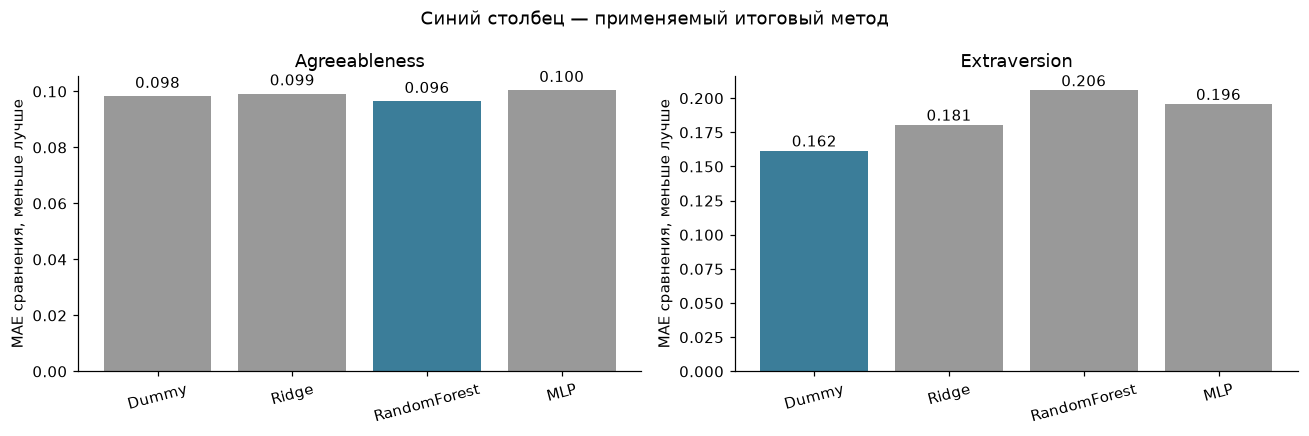

Для **Agreeableness** итоговый **RandomForest** получил MAE **0.096**, RMSE **0.116** и R² **-0.213**. MAE baseline составила 0.098. Разность MAE равнялась -0.002, 95% парный интервал [-0.031, +0.031]. Метод зафиксирован в протоколе, сравнительная выборка ранее участвовала в его выборе.

Для **Extraversion** итоговый **Dummy** получил MAE **0.162**, RMSE **0.192** и R² **-0.009**. MAE baseline составила 0.162. Разность MAE равнялась +0.000, 95% парный интервал [+0.000, +0.000]. Метод зафиксирован в протоколе, сравнительная выборка ранее участвовала в его выборе.

In [8]:
from sklearn.base import clone
metrics_rows, predictions_rows = [], []
for target in targets:
    truth = people.loc[test_ids,target].to_numpy()
    for name in ['Dummy','Ridge','RandomForest','MLP']:
        estimator = clone(fitted[(target,name)])
        t0 = time.perf_counter()
        estimator.fit(X_train, people.loc[train_ids,target])
        fit_seconds = time.perf_counter()-t0
        t0 = time.perf_counter()
        pred = estimator.predict(X_test)
        predict_seconds = time.perf_counter()-t0
        assert np.allclose(pred, fitted[(target,name)].predict(X_test), atol=1e-10)
        metrics_rows.append({'target':target,'model':name,'n_test':len(test_ids),
                             'MAE':mean_absolute_error(truth,pred),
                             'RMSE':np.sqrt(mean_squared_error(truth,pred)), 'R2':r2_score(truth,pred),
                             'fit_seconds':fit_seconds,'predict_seconds':predict_seconds,
                             'outside_0_1':int(((pred<0)|(pred>1)).sum()),
                             'applied':name==selected_final[target]})
        predictions_rows.extend({'Id_name':key,'target':target,'model':name,'actual':float(y),
                                 'prediction':float(p),'absolute_error':float(abs(y-p))}
                                for key,y,p in zip(test_ids,truth,pred))
metrics = pd.DataFrame(metrics_rows)
predictions = pd.DataFrame(predictions_rows)
metrics.to_csv(RESULTS / 'test_metrics.csv',index=False)
predictions.to_csv(RESULTS / 'test_predictions.csv',index=False)
display(metrics)

bootstrap_rows = []
for target in targets:
    name = selected_final[target]
    err = predictions.query('target == @target and model == @name').set_index('Id_name').loc[test_ids,'absolute_error'].to_numpy()
    dummy_err = predictions.query("target == @target and model == 'Dummy'").set_index('Id_name').loc[test_ids,'absolute_error'].to_numpy()
    difference = err-dummy_err
    idx = np.random.default_rng(SEED).integers(0,len(test_ids),size=(5000,len(test_ids)))
    means = difference[idx].mean(axis=1)
    low,high = np.quantile(means,[.025,.975])
    bootstrap_rows.append({'target':target,'selected_model':name,'delta_MAE_vs_Dummy':difference.mean(),
                           'CI95_low':low,'CI95_high':high,'bootstrap_repeats':5000})
bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(RESULTS / 'paired_bootstrap.csv',index=False)
display(bootstrap)

fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax,target in zip(axes,targets):
    m = metrics.query('target == @target')
    bars = ax.bar(m.model,m.MAE,color=['#999999' if not s else '#3b7d99' for s in m.applied])
    ax.set(title=target, ylabel='MAE сравнения, меньше лучше')
    for bar,val in zip(bars,m.MAE): ax.text(bar.get_x()+bar.get_width()/2,val+.003,f'{val:.3f}',ha='center')
    ax.tick_params(axis='x',rotation=15)
plt.suptitle('Синий столбец — применяемый итоговый метод')
plt.tight_layout()
savefig('04_model_comparison')
for target in targets:
    chosen = metrics.query('target == @target and applied').iloc[0]
    base = metrics.query("target == @target and model == 'Dummy'").iloc[0]
    boot = bootstrap.query('target == @target').iloc[0]
    display(Markdown(f"Для **{target}** итоговый **{chosen.model}** получил MAE **{chosen.MAE:.3f}**, "
                     f"RMSE **{chosen.RMSE:.3f}** и R² **{chosen.R2:.3f}**. "
                     f"MAE baseline составила {base.MAE:.3f}. Разность MAE равнялась "
                     f"{boot.delta_MAE_vs_Dummy:+.3f}, 95% парный интервал "
                     f"[{boot.CI95_low:+.3f}, {boot.CI95_high:+.3f}]. "
                     "Метод зафиксирован в протоколе, сравнительная выборка ранее участвовала в его выборе."))
metrics.query('applied').to_csv(RESULTS/'final_metrics.csv',index=False)
predictions[predictions.apply(lambda r:r.model==selected_final[r.target],axis=1)].to_csv(RESULTS/'final_predictions.csv',index=False)


## 8. Ошибки и неоднородность качества

Для каждой цели показываю три заранее определённые группы по истинному значению: [0, 1/3), [1/3, 2/3), [2/3, 1]. Порогами по ошибкам сравнения не управляю. Для каждой группы указываю размер, MAE выбранной модели и Dummy. Малые группы использую только для описания. По одному минимальному и максимальному абсолютному отклонению выбираю отдельно как крайние примеры. При равных ошибках сортирую по ID.

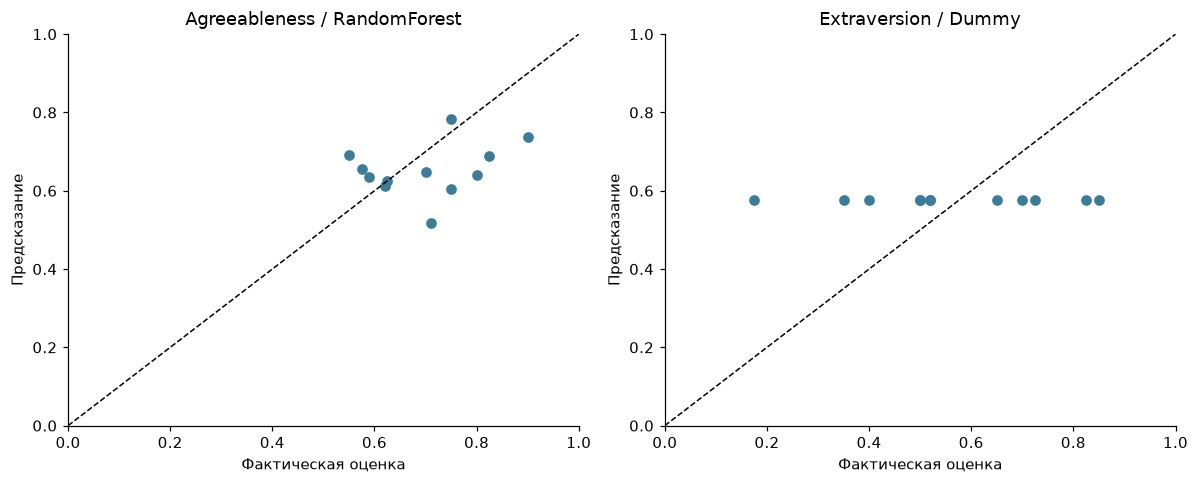

,target,model,group,n,model_MAE,Dummy_MAE
0,Agreeableness,RandomForest,"[0, 1/3)",0,NaN,NaN
1,Agreeableness,RandomForest,"[1/3, 2/3)",5,0.0555,0.0559
2,Agreeableness,RandomForest,"[2/3, 1]",7,0.1257,0.1285
3,Extraversion,Dummy,"[0, 1/3)",1,0.4025,0.4025
4,Extraversion,Dummy,"[1/3, 2/3)",7,0.1068,0.1068
5,Extraversion,Dummy,"[2/3, 1]",4,0.1975,0.1975


,target,case,Id_name,actual,prediction,absolute_error
0,Agreeableness,Минимальная ошибка,wDFVbbC_eNY,0.625,0.6252,0.0002
1,Agreeableness,Максимальная ошибка,PMoGeaZ_lek,0.710,0.5184,0.1916
2,Extraversion,Минимальная ошибка,CJySiDx_fZS,0.520,0.5775,0.0575
3,Extraversion,Максимальная ошибка,VVMgEJO_XFg,0.175,0.5775,0.4025


Для Agreeableness наибольшая ошибка составила **0.192**. При фактическом значении 0.710 модель выдала 0.518. Этот пример выбрал по максимуму ошибки, поэтому не считал его оценкой среднего качества.

Для Extraversion наибольшая ошибка составила **0.403**. При фактическом значении 0.175 модель выдала 0.578. Этот пример выбрал по максимуму ошибки, поэтому не считал его оценкой среднего качества.

In [9]:
group_rows, example_rows = [], []
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
for ax,target in zip(axes,targets):
    name = selected_final[target]
    part = predictions.query('target == @target and model == @name').set_index('Id_name').loc[test_ids].copy()
    base = predictions.query("target == @target and model == 'Dummy'").set_index('Id_name').loc[test_ids]
    part['group'] = pd.cut(part.actual,bins=[-1e-12,1/3,2/3,1+1e-12],right=False,
                           labels=['[0, 1/3)','[1/3, 2/3)','[2/3, 1]'])
    for group,rows in part.groupby('group',observed=False):
        group_rows.append({'target':target,'model':name,'group':str(group),'n':len(rows),
                           'model_MAE':rows.absolute_error.mean() if len(rows) else None,
                           'Dummy_MAE':base.loc[rows.index,'absolute_error'].mean() if len(rows) else None})
    ordered = part.reset_index().sort_values(['absolute_error','Id_name'])
    for label,row in [('Минимальная ошибка',ordered.iloc[0]),('Максимальная ошибка',ordered.iloc[-1])]:
        example_rows.append({'target':target,'case':label,'Id_name':row.Id_name,
                             'actual':row.actual,'prediction':row.prediction,'absolute_error':row.absolute_error})
    ax.scatter(part.actual,part.prediction,color='#3b7d99')
    limits = [min(0,part.prediction.min()),max(1,part.prediction.max())]
    ax.plot(limits,limits,'k--',lw=1)
    ax.set(title=target+' / '+name, xlabel='Фактическая оценка',ylabel='Предсказание',xlim=limits,ylim=limits)
plt.tight_layout()
savefig('05_predictions')
group_metrics = pd.DataFrame(group_rows)
examples = pd.DataFrame(example_rows)
group_metrics.to_csv(RESULTS / 'error_groups.csv',index=False)
examples.to_csv(RESULTS / 'extreme_examples.csv',index=False)
display(group_metrics)
display(examples)
for target in targets:
    row = examples.query("target == @target and case == 'Максимальная ошибка'").iloc[0]
    display(Markdown(f"Для {target} наибольшая ошибка составила **{row.absolute_error:.3f}**. "
                     f"При фактическом значении {row.actual:.3f} модель выдала {row.prediction:.3f}. "
                     "Этот пример выбрал по максимуму ошибки, поэтому не считал его оценкой среднего качества."))

## 9. Полные корреляции и интерпретация задания 2

После оценки зафиксированных методов вычисляю корреляции на всех 38 участниках для выполнения описательной части задания. Включаю пять черт и SE, всего 132 проверки. Для Spearman снова применяю перестановочный тест и BH ко всему этому семейству. Отдельно показываю заранее сформулированную пару «доля улыбок — экстраверсия» с нескорректированным и скорректированным p-value. Для доли улыбок дополнительно показываю число кадров с улыбкой как диагностический признак, оно не входит в перебор моделей.

,feature,target,n,pearson_r,pearson_p,spearman_rho,spearman_p_perm,spearman_q_BH,pearson_q_BH
0,smile_ratio,Extraversion,38,0.1339,0.4228,0.3526,0.0324,0.8554,0.9517
1,smile_ratio,Agreeableness,38,-0.1889,0.2562,0.0527,0.7398,0.9591,0.9517
2,smile_ratio,Conscientiousness,38,-0.1531,0.3587,-0.0764,0.6480,0.9591,0.9517
3,smile_ratio,Neuroticism,38,0.0827,0.6215,0.0601,0.7196,0.9591,0.9517
4,smile_ratio,Openness,38,0.0555,0.7407,0.1172,0.4908,0.9591,0.9517
5,smile_ratio,SE,38,0.2661,0.1064,0.3708,0.0236,0.7788,0.9517


,target,Pearson_raw_count,Spearman_raw_count
0,Extraversion,0.2154,0.3832
1,Agreeableness,-0.2293,0.0787
2,Conscientiousness,-0.1651,-0.0630
3,Neuroticism,0.0218,0.0250
4,Openness,-0.0129,0.1498
5,SE,0.2723,0.3926


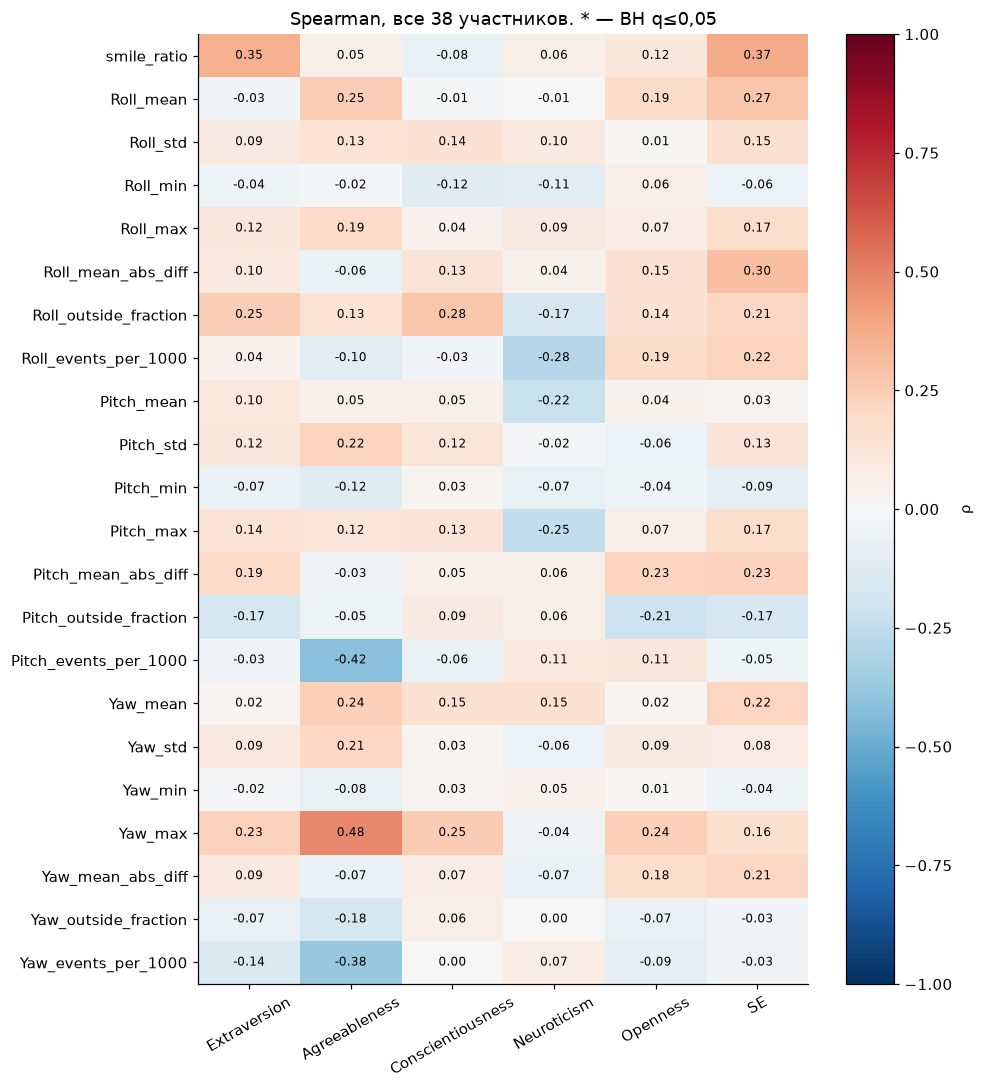

,feature,target,n,pearson_r,pearson_p,spearman_rho,spearman_p_perm,spearman_q_BH,pearson_q_BH,abs_rho
109,Yaw_max,Agreeableness,38,0.4842,0.0021,0.4803,0.0028,0.3696,0.2727,0.4803
85,Pitch_events_per_1000,Agreeableness,38,-0.3074,0.0605,-0.4177,0.0086,0.5676,0.9517,0.4177
127,Yaw_events_per_1000,Agreeableness,38,-0.2849,0.0829,-0.3798,0.0190,0.7788,0.9517,0.3798
45,Roll_events_per_1000,Neuroticism,38,-0.0935,0.5764,-0.2833,0.0934,0.9591,0.9517,0.2833
38,Roll_outside_fraction,Conscientiousness,38,0.2031,0.2214,0.2786,0.0900,0.9591,0.9517,0.2786
110,Yaw_max,Conscientiousness,38,0.2406,0.1457,0.2530,0.1216,0.9591,0.9517,0.2530
69,Pitch_max,Neuroticism,38,-0.1770,0.2878,-0.2496,0.1308,0.9591,0.9517,0.2496
7,Roll_mean,Agreeableness,38,0.1827,0.2721,0.2487,0.1290,0.9591,0.9517,0.2487


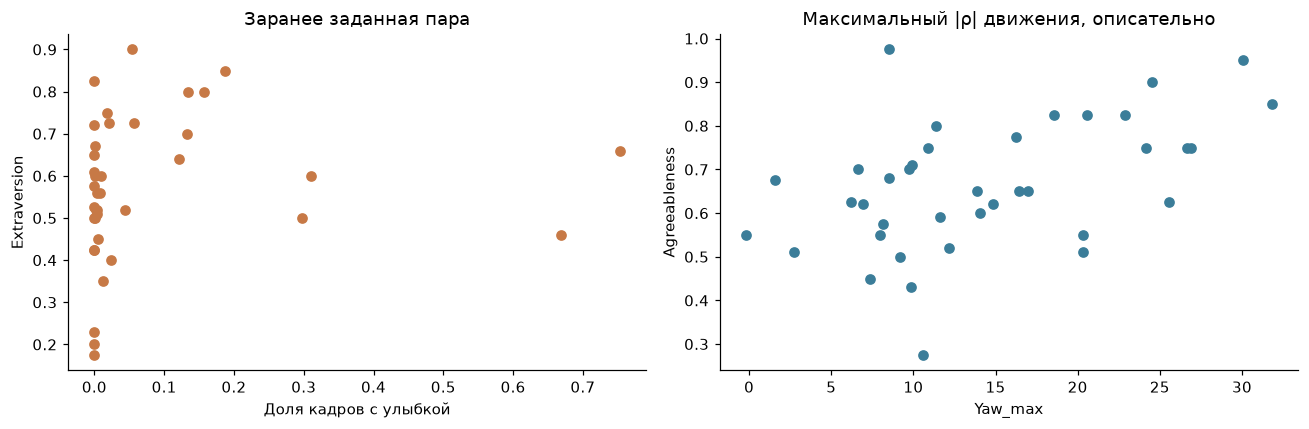

На всех участниках для улыбок и экстраверсии получил **Pearson r=0.134** и **Spearman ρ=0.353**. Перестановочное p-value составило 0.0324, BH q=0.8554. После поправки среди всех 132 проверок сохранилось 0 связей. Наиболее сильной наблюдаемой парой движений оказалась Yaw_max → Agreeableness, ρ=0.480, q=0.3696. Её выделил по максимуму на полной выборке и не считал независимым подтверждением. Гипотезы о движениях головы после этих графиков не добавлял в модели.

In [10]:
full_corr = correlation_table(features, people[traits+['SE']])
full_corr.to_csv(RESULTS / 'correlations_full.csv',index=False)
smile_corr = full_corr.query("feature == 'smile_ratio'").copy()
display(smile_corr)
raw_smile = pd.DataFrame([{'target':t,'Pearson_raw_count':pearsonr(audit.smiles,people[t]).statistic,
                          'Spearman_raw_count':spearmanr(audit.smiles,people[t]).statistic}
                         for t in traits+['SE']])
display(raw_smile)
raw_smile.to_csv(RESULTS / 'raw_smile_count_correlations.csv',index=False)

matrix = full_corr.pivot(index='feature',columns='target',values='spearman_rho').reindex(index=features.columns,columns=traits+['SE'])
q_matrix = full_corr.pivot(index='feature',columns='target',values='spearman_q_BH').reindex_like(matrix)
fig, ax = plt.subplots(figsize=(9,10))
im = ax.imshow(matrix.to_numpy(),cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
ax.set(xticks=range(len(matrix.columns)),xticklabels=matrix.columns,yticks=range(len(matrix)),yticklabels=matrix.index,
       title='Spearman, все 38 участников. * — BH q≤0,05')
ax.tick_params(axis='x',rotation=30)
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        star = '*' if q_matrix.iloc[i,j]<=.05 else ''
        ax.text(j,i,f'{matrix.iloc[i,j]:.2f}'+star,ha='center',va='center',fontsize=8)
plt.colorbar(im,ax=ax,label='ρ')
plt.tight_layout()
savefig('06_correlation_heatmap')

smile_e = smile_corr.query("target == 'Extraversion'").iloc[0]
motion_corr = full_corr.query("feature != 'smile_ratio' and target != 'SE'").copy()
motion_corr['abs_rho'] = motion_corr.spearman_rho.abs()
top_motion = motion_corr.sort_values(['abs_rho','feature','target'],ascending=[False,True,True]).iloc[0]
display(motion_corr.sort_values('abs_rho',ascending=False).head(8))

fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(features.smile_ratio,people.Extraversion,color='#c77946')
axes[0].set(xlabel='Доля кадров с улыбкой',ylabel='Extraversion',title='Заранее заданная пара')
axes[1].scatter(features[top_motion.feature],people[top_motion.target],color='#3b7d99')
axes[1].set(xlabel=top_motion.feature,ylabel=top_motion.target,title='Максимальный |ρ| движения, описательно')
plt.tight_layout()
savefig('07_correlations_scatter')
display(Markdown(f"На всех участниках для улыбок и экстраверсии получил **Pearson r={smile_e.pearson_r:.3f}** "
                 f"и **Spearman ρ={smile_e.spearman_rho:.3f}**. Перестановочное p-value составило "
                 f"{smile_e.spearman_p_perm:.4f}, BH q={smile_e.spearman_q_BH:.4f}. "
                 f"После поправки среди всех 132 проверок сохранилось {full_corr.spearman_q_BH.le(.05).sum()} связей. "
                 f"Наиболее сильной наблюдаемой парой движений оказалась {top_motion.feature} → {top_motion.target}, "
                 f"ρ={top_motion.spearman_rho:.3f}, q={top_motion.spearman_q_BH:.4f}. "
                 "Её выделил по максимуму на полной выборке и не считал независимым подтверждением. "
                 "Гипотезы о движениях головы после этих графиков не добавлял в модели."))